# Zadanie 1 i 2

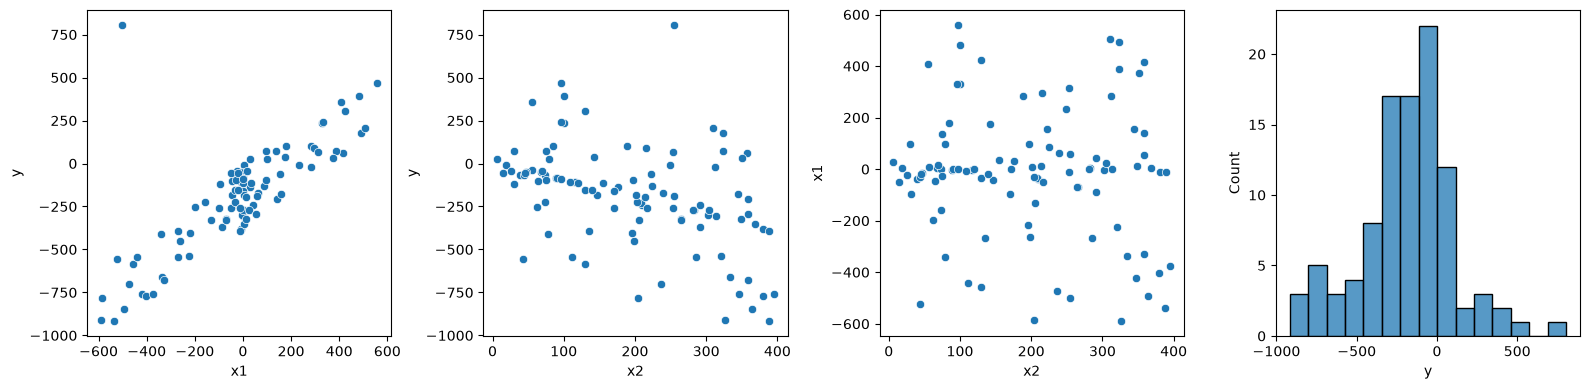

Współczynnik korelacji Perasona dla wykresu x1 od x2: -0.10331575849372848
Współczynnik korelacji Perasona dla wykresu y od x2: -0.44093412497640655
Współczynnik korelacji Perasona dla wykresu y od x1: 0.7807075119131058


In [49]:
# Zależność y od x1 lub x2 oraz x1 od x2
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data1.csv");
f, axs = plt.subplots(1, 4, figsize=(16, 4))
sns.scatterplot(data=df, x="x1", y="y", ax=axs[0])
sns.scatterplot(data=df, x="x2", y="y", ax=axs[1])
sns.scatterplot(data=df, x="x2", y="x1", ax=axs[2])
sns.histplot(data=df, x="y")
f.tight_layout()
plt.show()

# Jaki jest współczynnik korealcji Perasona dla wykresu x1 od x2?
print("Współczynnik korelacji Perasona dla wykresu x1 od x2:", df["x2"].corr(df["x1"], method='pearson'))
print("Współczynnik korelacji Perasona dla wykresu y od x2:", df["x2"].corr(df["y"], method='pearson'))
print("Współczynnik korelacji Perasona dla wykresu y od x1:", df["x1"].corr(df["y"], method='pearson'))

### Wnioski: 
- x1, x2 są niezależne liniowo
- Widać powiązanie y z x1
- O wiele gorzej, ale widać powiązanie y z x2
- W obu wykresach y od x1 oraz y od x2 występują skrajne outliery, będzie trzeba to uwzględnić przy wyborze funkcji straty
- Możliwe że warto będzie porównać 3 wersje modelu: wersja z samą cechą x1, wersja z obiema cechami oraz wersja z cechą x1
- Istnieją pojedyńcze bardzo duże odchylenia `y` - możliwe że warto się ich pozbyć

### Sprzątanie danych
Możemy w preprocessingu usunąć 1% outlierów z `y` aby mieć czystsze dane do nauki

In [98]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.61 + 1.00x_1 + -1.00x_2
MAE Modelu z cechami x1, x2 (po usunieciu outlierów): 0.5886
MSE Modelu z cechami x1, x2 (po usunieciu outlierów): 0.4776


### Teraz porównajmy co by się stało gdyby pozbyć się x2 z modelu

In [69]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")

X = df[["x1"]]
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = -193.24 + 1.00x_1
MAE Modelu z cechami x1 (po usunieciu outlierów): 116.0044
MSE Modelu z cechami x1 (po usunieciu outlierów): 15650.9748


### Wniosek - i tak lepiej jest użyć obu cech
Pomysł: czy połączenie cechy x1 i x2 w nową ceche zminimalizuje błąd bardziej?

### Wykresy różnych wersji nowych cech

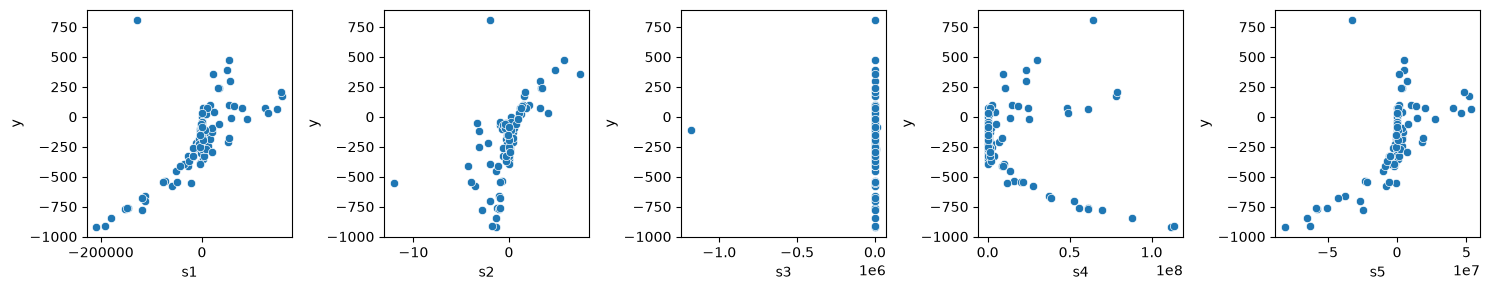

In [97]:
# (Wykresy) Zależność y od x1 lub x2 oraz x1 od x2
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data1.csv");
df["s1"] = df["x1"] * df["x2"]
df["s2"] = df["x1"] / (df["x2"] + 1e-12)
df["s3"] = df["x2"] / (df["x1"] + 1e-12)
df["s4"] = df["x1"] * df["x1"] * df["x2"]
df["s5"] = df["x1"] * df["x2"] * df["x2"]

f, axs = plt.subplots(1, 5, figsize=(15, 3))
sns.scatterplot(data=df, x="s1", y="y", ax=axs[0])
sns.scatterplot(data=df, x="s2", y="y", ax=axs[1])
sns.scatterplot(data=df, x="s3", y="y", ax=axs[2])
sns.scatterplot(data=df, x="s4", y="y", ax=axs[3])
sns.scatterplot(data=df, x="s5", y="y", ax=axs[4])
f.tight_layout()
plt.show()

In [77]:
# Test nowej cechy s = x1 * x2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")
df["s"] = df["x1"] * df["x2"]

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_1 * x_2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.58 + 1.00x_1 + -1.00x_2 + 0.00x_1 * x_2
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.6604
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.5682


In [95]:
# Test nowej cechy s = x1 / x2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")
df["s"] = df["x1"] / (df["x2"] + 1e-10)

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_1 * x_2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.56 + 1.00x_1 + -1.00x_2 + -0.14x_1 * x_2
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.6846
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.5950


In [100]:
# Test nowej cechy s = x2 / x1
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")
df["s"] = df["x2"] / (df["x1"] + 1e-12)

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_2 / x_1^2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.67 + 1.00x_1 + -1.00x_2 + 0.00x_2 / x_1^2
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.5843
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.4697


## Konkluzja
Jedyne co miało sens to czyszczenie outlierów `y` oraz dodanie nowej cechy `s = x2 / x1`. Ale nie wiem czy moge dodać nowej cechy akurat w tym zadaniu

In [28]:
# Test modelu na danych testowych
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")


X = df.drop(columns=["y"])
y = df["y"]
X["s"] = X["x2"] / (X["x1"] + 1e-12);

X, y = preprocess_data(X, y)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_2 / x_1")
y_test_pred = model.predict(X_test)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_test, y_test_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_test, y_test_pred):.4f}")

Znaleziona prosta: y = 8.15 + 1.00x_1 + -1.00x_2 + 0.00x_2 / x_1
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.8606
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 1.2856


In [29]:
# Porównanie na danych testowych modelu baseline (sama regresja po x1 i x2 bez czyszczenia)
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression


df = pd.read_csv("data1.csv")


X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2")
y_test_pred = model.predict(X_test)
print(f"MAE Modelu z cechami x1, x2: {mean_absolute_error(y_test, y_test_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2: {mean_squared_error(y_test, y_test_pred):.4f}")

Znaleziona prosta: y = 11.50 + 0.84x_1 + -0.92x_2
MAE Modelu z cechami x1, x2: 32.8123
MSE Modelu z cechami x1, x2: 1817.8859


In [30]:
# Porównanie na danych testowych modelu baseline (sama regresja po x1 i x2 + czyszczenie)
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")


X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2")
y_test_pred = model.predict(X_test)
print(f"MAE Modelu z cechami x1, x2: {mean_absolute_error(y_test, y_test_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2: {mean_squared_error(y_test, y_test_pred):.4f}")

Znaleziona prosta: y = 7.61 + 1.00x_1 + -1.00x_2
MAE Modelu z cechami x1, x2: 0.9430
MSE Modelu z cechami x1, x2: 1.2816


# Zadanie 3
Zakładam że dane advertising.csv to jakieś porównanie ilość reklam puszczonych w danym medium oraz sprzedarz produktu reklamowanego

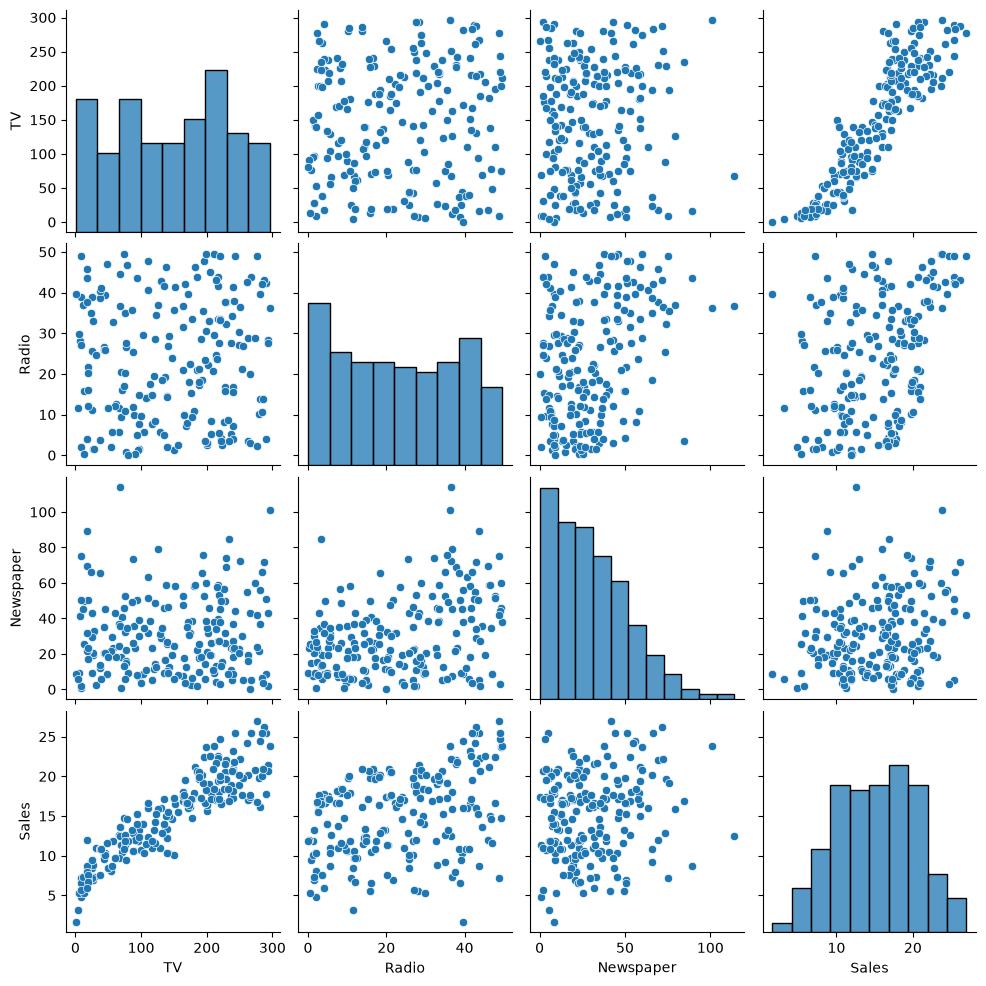

In [31]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("advertising.csv");
sns.pairplot(df)
plt.show()
# f, axs = plt.subplots(1, 4, figsize=(16, 4))
# sns.scatterplot(data=df, x="Radio", y="Sales", ax=axs[0])
# sns.scatterplot(data=df, x="Newspaper", y="Sales", ax=axs[1])
# sns.scatterplot(data=df, x="TV", y="Sales", ax=axs[2])
# sns.histplot(data=df, x="Sales")
# f.tight_layout()
# plt.show()

# print("Współczynnik korelacji Perasona dla wykresu Sales od Radio:", df["Radio"].corr(df["Sales"], method='pearson'))
# print("Współczynnik korelacji Perasona dla wykresu Sales od Newspaper:", df["Newspaper"].corr(df["Sales"], method='pearson'))
# print("Współczynnik korelacji Perasona dla wykresu Sales od TV:", df["TV"].corr(df["Sales"], method='pearson'))

In [22]:
# Krok 1: Prosta regresja po prostu po wszystkich cechach bez normalizacji
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_val)
print(f"MAE Modelu: {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_val, y_val_pred):.4f}")

MAE Modelu: 1.2803
MSE Modelu: 2.5230


In [40]:
# Krok 2: Prosta regresja po prostu po wszystkich cechach ale normalizujemy dane
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

def normalize(X, X_train):
    X_copy = X.copy()
    X_copy["TV"] = (X_copy["TV"] - X_train["TV"].mean()) / X_train["TV"].std()
    X_copy["Radio"] = (X_copy["Radio"] - X_train["Radio"].mean()) / X_train["Radio"].std()
    X_copy["Newspaper"] = (X_copy["Newspaper"] - X_train["Newspaper"].mean()) / X_train["Newspaper"].std()
    return X_copy

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train_raw = X_train.copy()
X_train = normalize(X_train, X_train_raw)
X_val = normalize(X_val, X_train_raw)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_val)
print(f"MAE Modelu: {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_val, y_val_pred):.4f}")

MAE Modelu: 1.2803
MSE Modelu: 2.5230


Póki co normalizacja za bardzo nic nie dała, tak jak w sumie się spodziewałem. Ale teraz spróbujemy na ciekawszym modelu

#### Hipoteza: na sprzedaż wpływa...
1. Skala reklam, czyli nie ważne gdzie robimy reklamy, ale jeżeli jest ich bardzo dużo to sprzedaży też pewnie będzie bardzo dużo
2. Rozkład reklam po mediach bo np. relatywnie dużo reklam w telewizji ewidentnie pozytywnie wpływa na sprzedaż

Pytanie jak znormalizować te ilości przy mediach żeby móc mieć stosunek ich między sobą czyt. jak przetłumaczyć je na wspólną jednostkę?

In [61]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

def preprocess_data(X, y):
    X_copy = X.copy()
    X_copy["total"] = X_copy['TV'] + X_copy['Radio'] + X_copy['Newspaper']
    X_copy['TV'] = X_copy['TV'] / (X_copy['TV'] + X_copy['Radio'] + X_copy['Newspaper'])
    X_copy['Radio'] = X_copy['Radio'] / (X_copy['TV'] + X_copy['Radio'] + X_copy['Newspaper'])
    X_copy['Newspaper'] = X_copy['Newspaper'] / (X_copy['TV'] + X_copy['Radio'] + X_copy['Newspaper'])
    return X_copy, y

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)
X_val, y_val = preprocess_data(X_val, y_val)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_val)
print(f"MAE Modelu: {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_val, y_val_pred):.4f}")

MAE Modelu: 1.3048
MSE Modelu: 2.5282


No dobra chyba jednak to był zły pomysł.

Teraz pomysł jest taki że zależność Sales od TV wygląda troche jak sqrt(Ax) + C, więc dodajmy jeszcze jedną ceche `TV_2 = TV * TV`

In [71]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

def preprocess_data(X, y):
    X_copy = X.copy()
    X_copy['TV_2'] = X_copy['TV'] * X_copy['TV']
    return X_copy, y

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)
X_val, y_val = preprocess_data(X_val, y_val)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_val)
print(f"MAE Modelu: {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_val, y_val_pred):.4f}")

MAE Modelu: 1.1179
MSE Modelu: 1.8566


Na tych konkretnych danych treningowych widać lekką poprawe, ale czy pomysł utrzyma się na żywych danych? Kto wie.

Pomysł kolejny: Nasze wykresy dosyć jasno pokazują że Newspaper i Radio mają kompletny szum jeżeli chodzi o relacje do Sales - może dobrym pomysłem byłoby po prostu usunięcie ich z modelu?

In [69]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

def preprocess_data(X, y):
    X_copy = X.copy()
    X_copy['TV_2'] = X_copy['TV'] * X_copy['TV']
    X_copy = X_copy.drop(columns=["Newspaper"])
    return X_copy, y

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)
X_val, y_val = preprocess_data(X_val, y_val)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_val)
print(f"MAE Modelu: {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_val, y_val_pred):.4f}")

MAE Modelu: 1.0643
MSE Modelu: 1.7276


[*Metodą prób i błędów*] okazuje się że usunięcie z cech "Newspaper" znacznie zmniejszyło MAE oraz MSE na danych treningowych - miałoby to sens bo kto normalny czyta gazety w 21 wieku (chociaż dane mogą być znacznie starsze).

Na koniec możemy jeszcze znormalizować kolumny

In [74]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

def normalize(X, X_train):
    X_copy = X.copy()
    X_copy["TV"] = (X_copy["TV"] - X_train["TV"].mean()) / X_train["TV"].std()
    X_copy["TV_2"] = (X_copy["TV_2"] - X_train["TV_2"].mean()) / X_train["TV_2"].std()
    X_copy["Radio"] = (X_copy["Radio"] - X_train["Radio"].mean()) / X_train["Radio"].std()
    return X_copy

def preprocess_data(X, y):
    X_copy = X.copy()
    X_copy['TV_2'] = X_copy['TV'] * X_copy['TV']
    X_copy = X_copy.drop(columns=["Newspaper"])
    return X_copy, y

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)
X_val, y_val = preprocess_data(X_val, y_val)

X_train_copy = X_train.copy()

X_train = normalize(X_train, X_train_copy)
X_val = normalize(X_val, X_train_copy)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_val)
print(f"MAE Modelu: {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_val, y_val_pred):.4f}")

MAE Modelu: 1.0643
MSE Modelu: 1.7276


...nic to nie dało.

Teraz przetestujmy pierwszy model i ostatni na danych testowych

In [75]:
# Pierwszy model
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_test)
print(f"MAE Modelu: {mean_absolute_error(y_test, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_test, y_val_pred):.4f}")

MAE Modelu: 1.1773
MSE Modelu: 2.9036


In [77]:
# Finalny model
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

df = pd.read_csv("advertising.csv")
X = df.drop(columns=["Sales"])
y = df["Sales"]

def preprocess_data(X, y):
    X_copy = X.copy()
    X_copy['TV_2'] = X_copy['TV'] * X_copy['TV']
    X_copy = X_copy.drop(columns=["Newspaper"])
    return X_copy, y

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)
X_test, y_test = preprocess_data(X_test, y_test)

model = LinearRegression()
model.fit(X_train, y_train)
y_val_pred = model.predict(X_test)
print(f"MAE Modelu: {mean_absolute_error(y_test, y_val_pred):.4f}")
print(f"MSE Modelu: {mean_squared_error(y_test, y_val_pred):.4f}")

MAE Modelu: 1.0697
MSE Modelu: 1.9719


Faktycznie lepsze dobranie cech poprawiło wynik modelu